## Setup

In [1]:
# Load libraries and the API key from .env
import csv
import random
from dotenv import load_dotenv
load_dotenv()

from anthropic import Anthropic
from anthropic.types import Message

# Create the client and choose the model
# (if the API says this model cannot run code, try a larger model such as claude-sonnet-4-5)
client = Anthropic()
model = "claude-haiku-4-5"

# Beta flags that switch on the Files API and the code execution tool
BETAS = ["files-api-2025-04-14", "code-execution-2025-05-22"]

## Message helpers

In [2]:
# Add a user turn; accepts text, a list of blocks, or a Message
def add_user_message(messages, message):
    messages.append({
        "role": "user",
        "content": message.content if isinstance(message, Message) else message,
    })

# Add an assistant turn
def add_assistant_message(messages, message):
    messages.append({
        "role": "assistant",
        "content": message.content if isinstance(message, Message) else message,
    })

# Chat function that enables the beta features and returns the full message
def chat(messages, tools=None, max_tokens=4000):
    params = {
        "model": model,
        "max_tokens": max_tokens,
        "messages": messages,
        "betas": BETAS,
    }
    if tools:
        params["tools"] = tools
    return client.beta.messages.create(**params)

## Create a sample streaming.csv

In [3]:
# Generate 500 fake subscribers, where more support interactions raise the churn chance
random.seed(42)  # fixed seed makes the file repeatable

rows = []
for i in range(1, 501):
    tier = random.choice(["Basic", "Standard", "Premium"])
    hours = round(random.uniform(0, 80), 1)
    support = random.randint(0, 8)
    price = {"Basic": 7.99, "Standard": 12.99, "Premium": 17.99}[tier]

    # Churn probability rises with support interactions and falls with viewing hours
    p = 0.10 + 0.07 * support - 0.002 * hours
    churned = "Yes" if random.random() < max(0.02, min(0.9, p)) else "No"

    rows.append([f"USER_{i:05d}", tier, price, hours, support, churned])

with open("streaming.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["UserID", "SubscriptionTier", "MonthlyPrice",
                     "TotalViewingHoursLastMonth", "CustomerServiceInteractions", "Churned"])
    writer.writerows(rows)

print("Created streaming.csv with", len(rows), "rows")

Created streaming.csv with 500 rows


## Upload the file with the Files API

In [4]:
# Upload once and keep the returned file id, instead of sending raw data each time
with open("streaming.csv", "rb") as f:
    file_metadata = client.beta.files.upload(file=("streaming.csv", f, "text/csv"))

print("File id:", file_metadata.id)

File id: file_01XGyKCfWxSLtsKgX96cnBmo


## Ask Claude to analyse the file with code execution

In [5]:
# The container_upload block makes the file available inside Claude's sandbox
messages = []
add_user_message(messages, [
    {
        "type": "text",
        "text": (
            "Run a detailed analysis to determine major drivers of churn. "
            "Your final output should include at least one detailed plot summarizing your findings."
        ),
    },
    {"type": "container_upload", "file_id": file_metadata.id},
])

# The tool schema is a small fixed stub, since Anthropic runs the code for you
response = chat(
    messages,
    tools=[{"type": "code_execution_20250522", "name": "code_execution"}],
)
print("stop_reason:", response.stop_reason)

stop_reason: max_tokens


## Inspect the block types

In [6]:
# Show every block: Claude's text, the code it ran, and the results
for i, block in enumerate(response.content):
    print(f"--- Block {i}: {block.type}")

    if block.type == "text":
        print(block.text[:400])

    elif block.type == "server_tool_use":
        # The Python code Claude decided to run
        print(str(block.input)[:400])

    elif block.type == "code_execution_tool_result":
        result = block.content
        # Printed output from the run (some versions use different attribute names)
        print("stdout:", getattr(result, "stdout", "")[:300])
        print("stderr:", getattr(result, "stderr", "")[:200])

--- Block 0: text
I'll help you analyze the major drivers of churn. Let me start by loading and exploring the data.
--- Block 1: server_tool_use
{'code': '\nimport pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nimport seaborn as sns\nfrom scipy.stats import chi2_contingency, pointbiserialr, spearmanr\nfrom sklearn.preprocessing import LabelEncoder\nimport warnings\nwarnings.filterwarnings(\'ignore\')\n\n# Load the data\ndf = pd.read_csv(\'/tmp/inputs/streaming.csv\')\n\n# Display basic information\nprint("Dataset Shape:
--- Block 2: code_execution_tool_result
stdout: 
stderr: Traceback (most recent call last):
  File "/code/01b2e3b62a86407aa71302a9d72e71e9.py", line 12, in <module>
    df = pd.read_csv('/tmp/inputs/streaming.csv')
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
--- Block 3: text
Let me check the correct path:
--- Block 4: server_tool_use
{'code': '\nimport os\nprint("Current directory:", os.getcwd())\nprint("\\nFiles in current directory:")\nprint(os.lis

## Read the final analysis

In [7]:
# Join only the text blocks to get Claude's written conclusion
analysis = "\n".join(b.text for b in response.content if b.type == "text")
print(analysis)

I'll help you analyze the major drivers of churn. Let me start by loading and exploring the data.
Let me check the correct path:
Now let me load the data with the correct path:
Now let's perform a detailed churn analysis:
Let me combine the code:
Excellent! Now let me create a detailed comprehensive visualization:
Let me fix the import issue:
Now let me create a detailed summary report:
Let me consolidate everything:
Perfect! Now let me create one more detailed plot highlighting the key insights:
Let me fix this:
Perfect! Now let me create a summary document:
Perfect! Let me create one final summary visualization:
Perfect! Let me create one final summary table:
Perfect! Now let me create a final visual summary:
Perfect! Let me create one final comprehensive summary document:


## Find the files Claude generated

In [8]:
# Plots live in the container, and their file ids appear in code_execution_output blocks
generated_ids = []

for block in response.content:
    if block.type == "code_execution_tool_result":
        content = getattr(block.content, "content", None) or []
        for item in content:
            if getattr(item, "type", "") == "code_execution_output":
                generated_ids.append(item.file_id)

print("Generated file ids:", generated_ids)

Generated file ids: ['file_01XMpLKFoiEgbvuBMjTUFGTa', 'file_016yLSxhukg9JQAMQa3WNJh2', 'file_01QbQBHZqeNjvfJ1mueLTcfQ', 'file_01PU95s6FfzCE1quznnttCim', 'file_01KsR6iga1jA5YRhjoKDqDx4']


## Download the plots

In [9]:
# Download each generated file through the Files API
for n, file_id in enumerate(generated_ids, start=1):
    downloaded = client.beta.files.download(file_id)
    path = f"churn_plot_{n}.png"
    downloaded.write_to_file(path)
    print("Saved", path)

Saved churn_plot_1.png
Saved churn_plot_2.png
Saved churn_plot_3.png
Saved churn_plot_4.png
Saved churn_plot_5.png


## Display the plots in the notebook

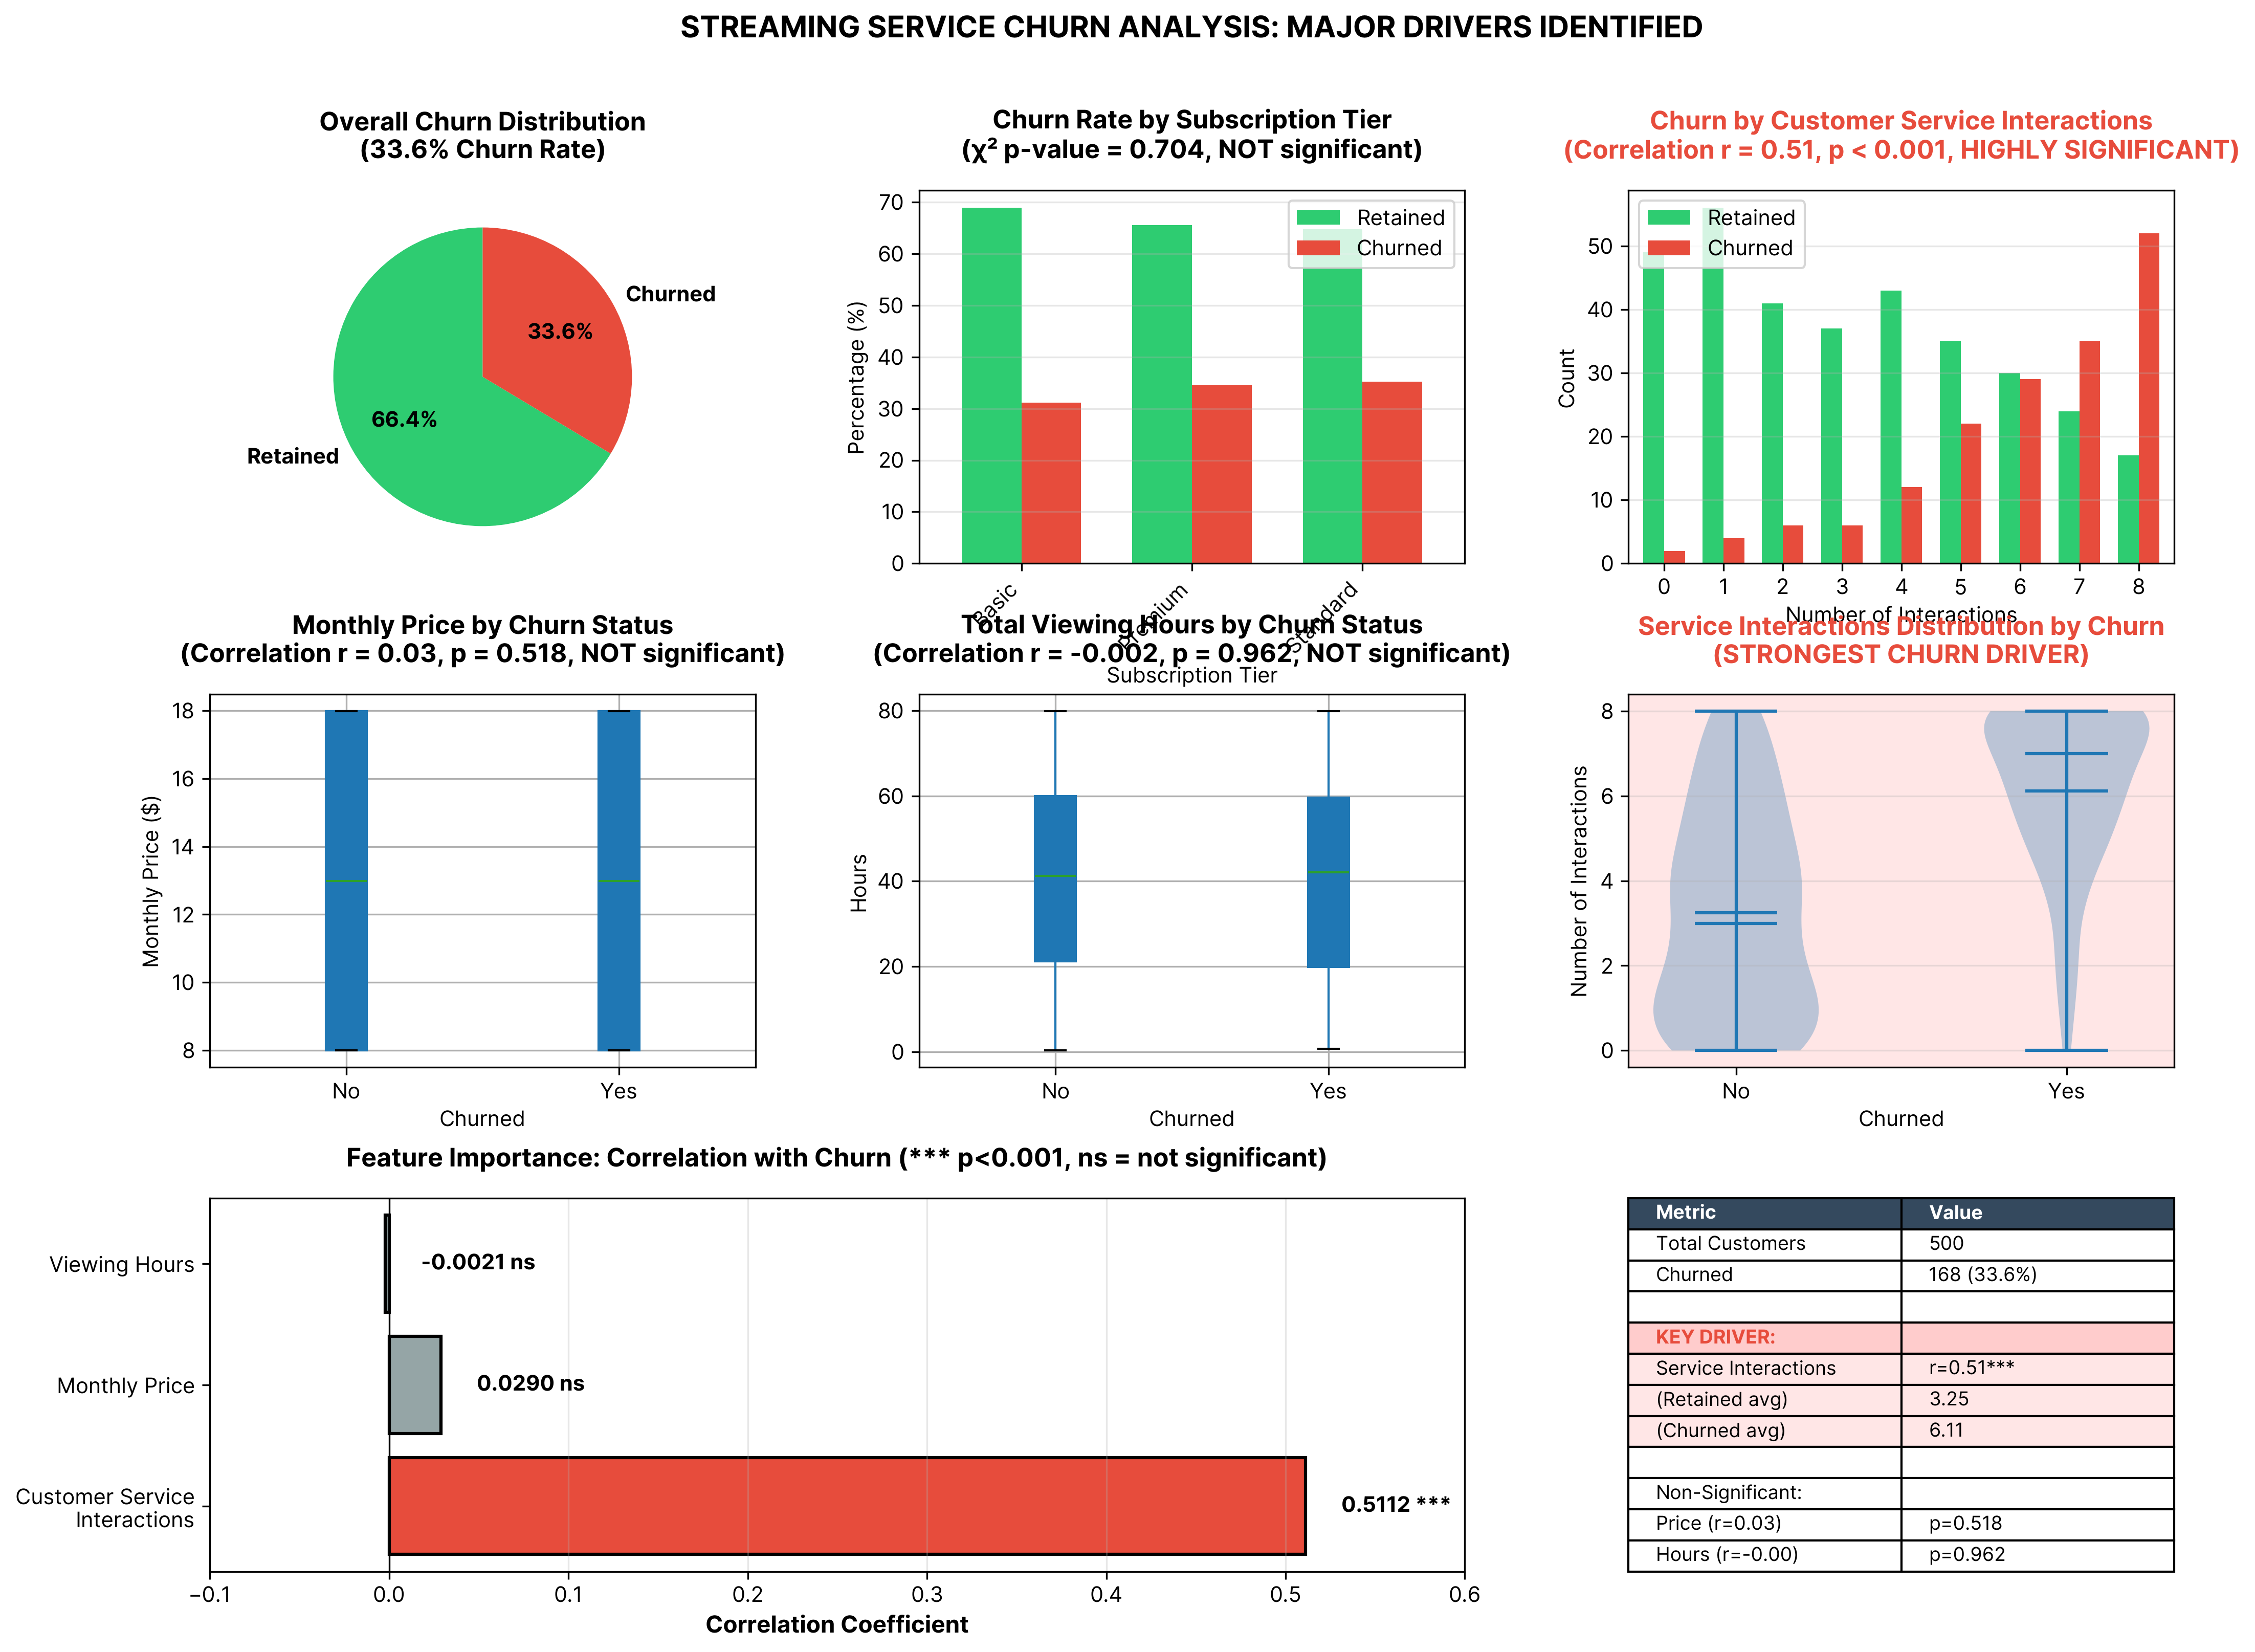

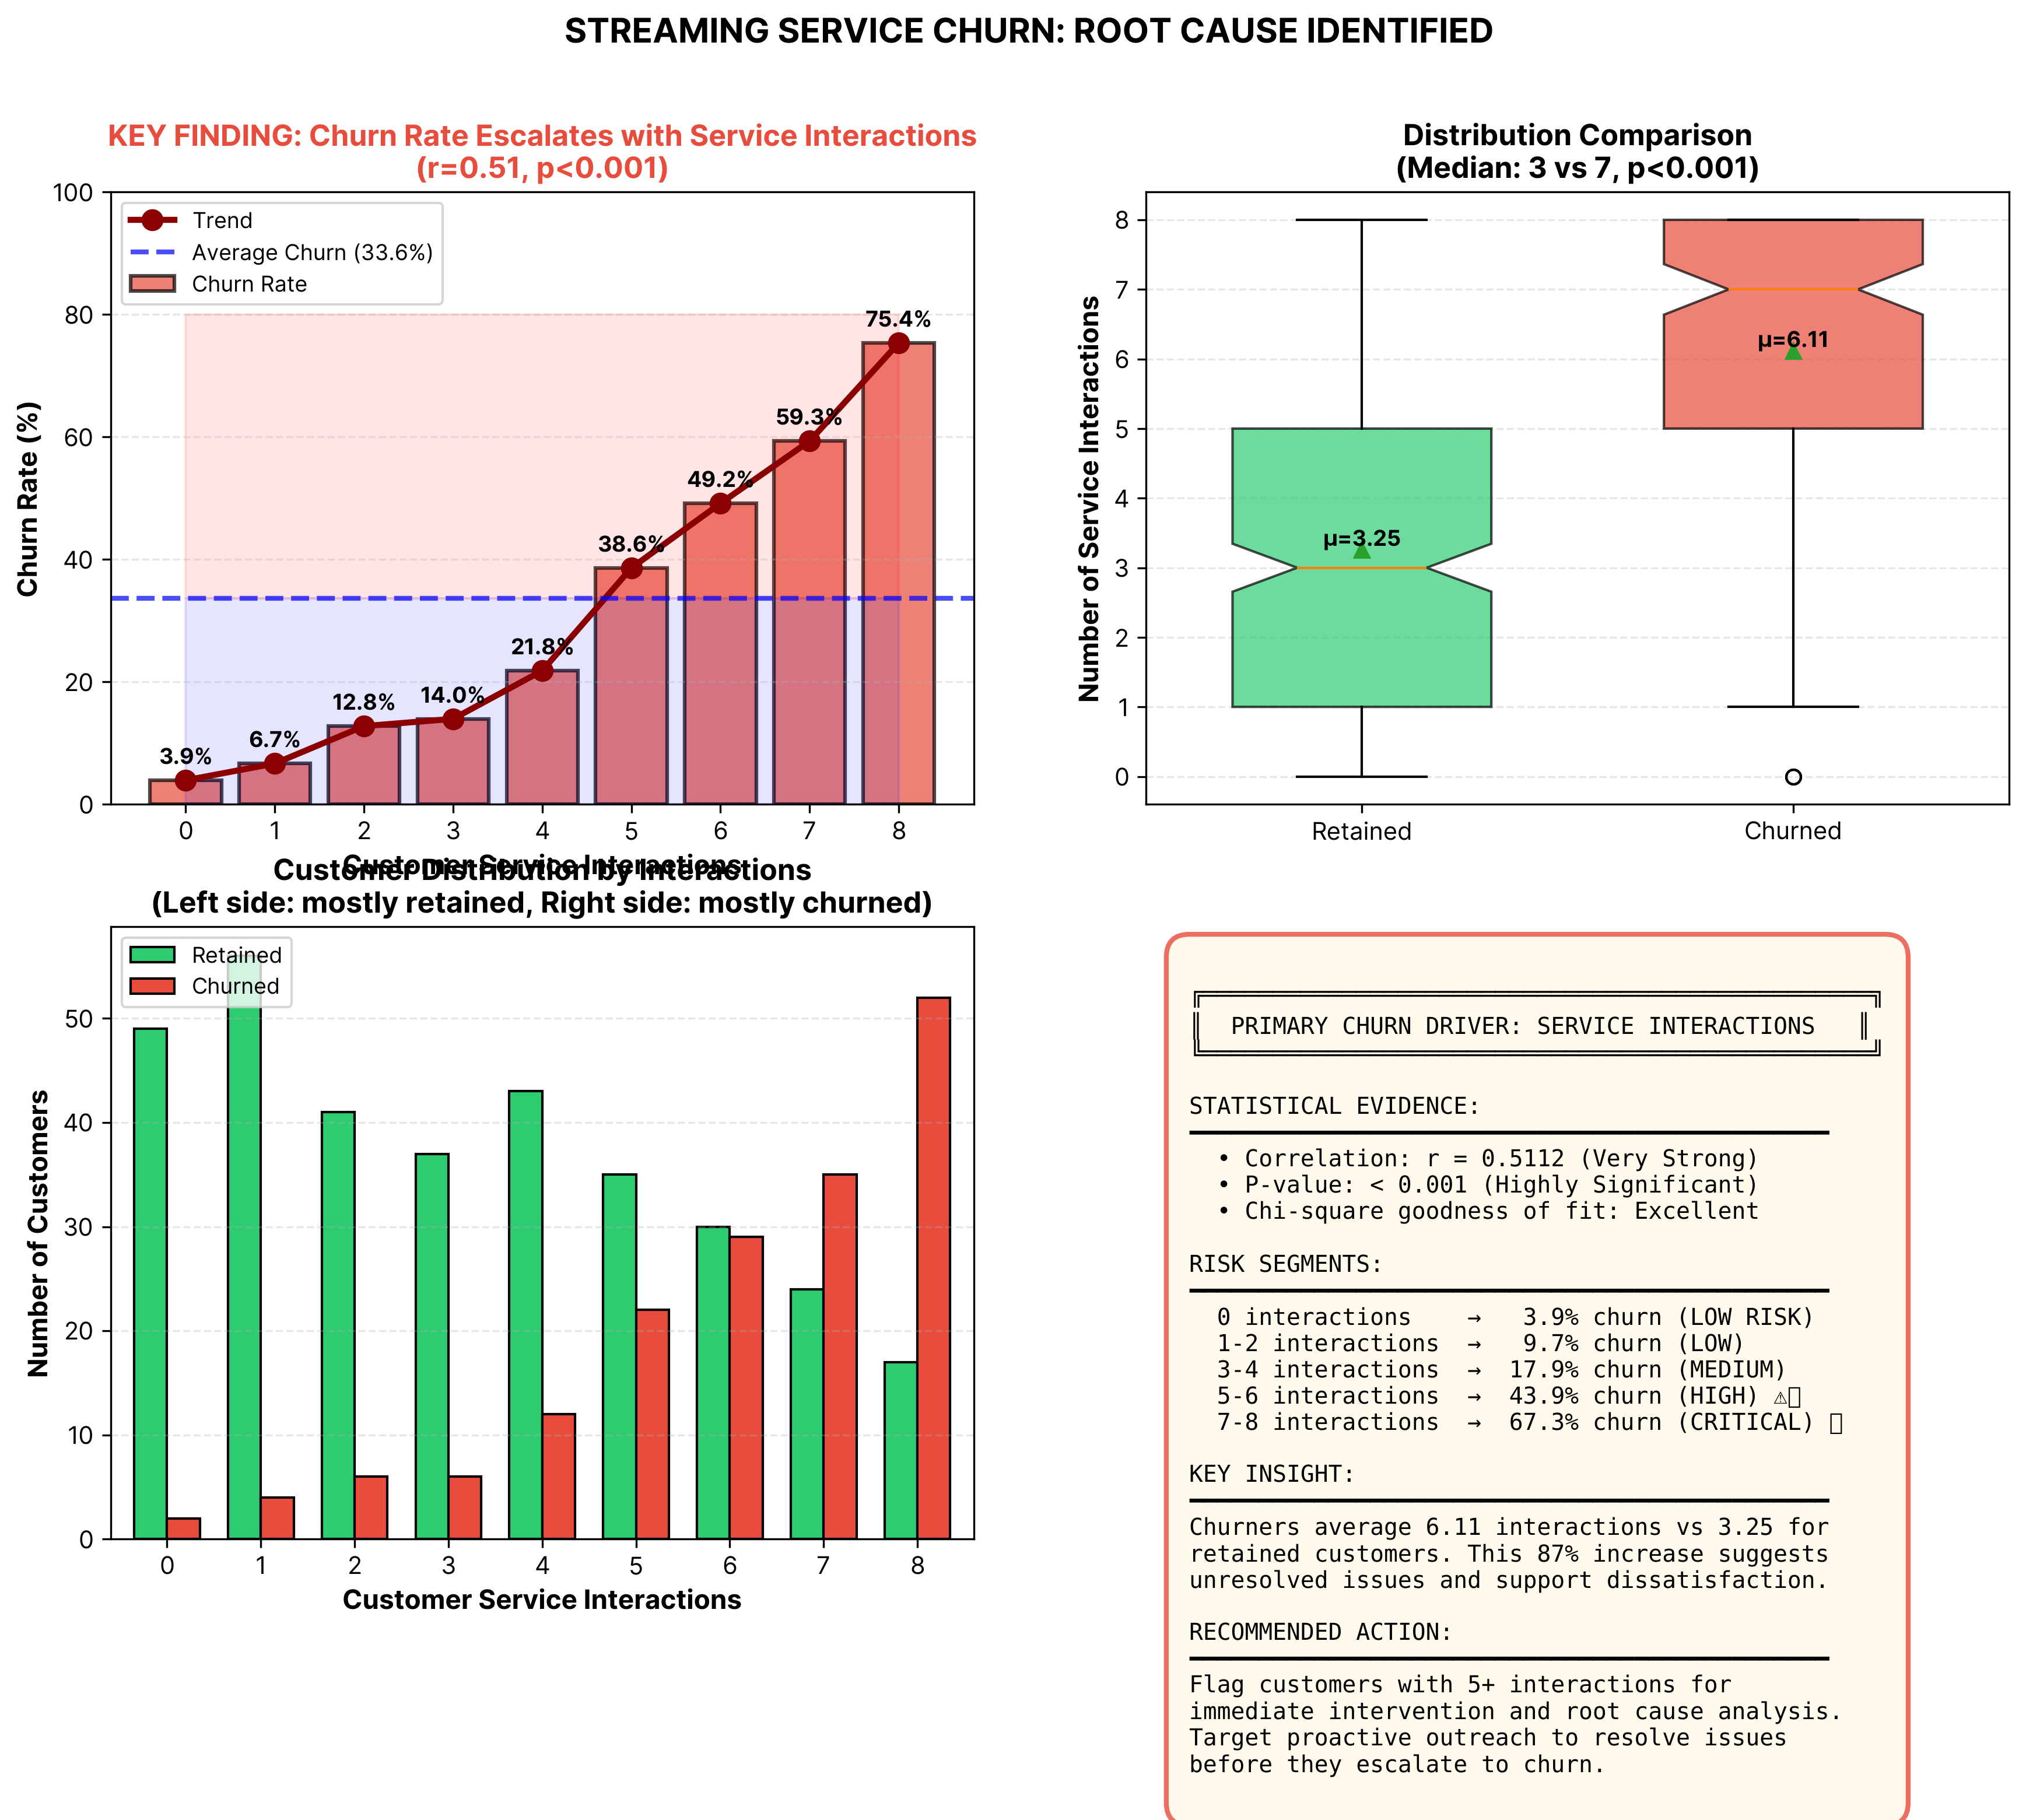

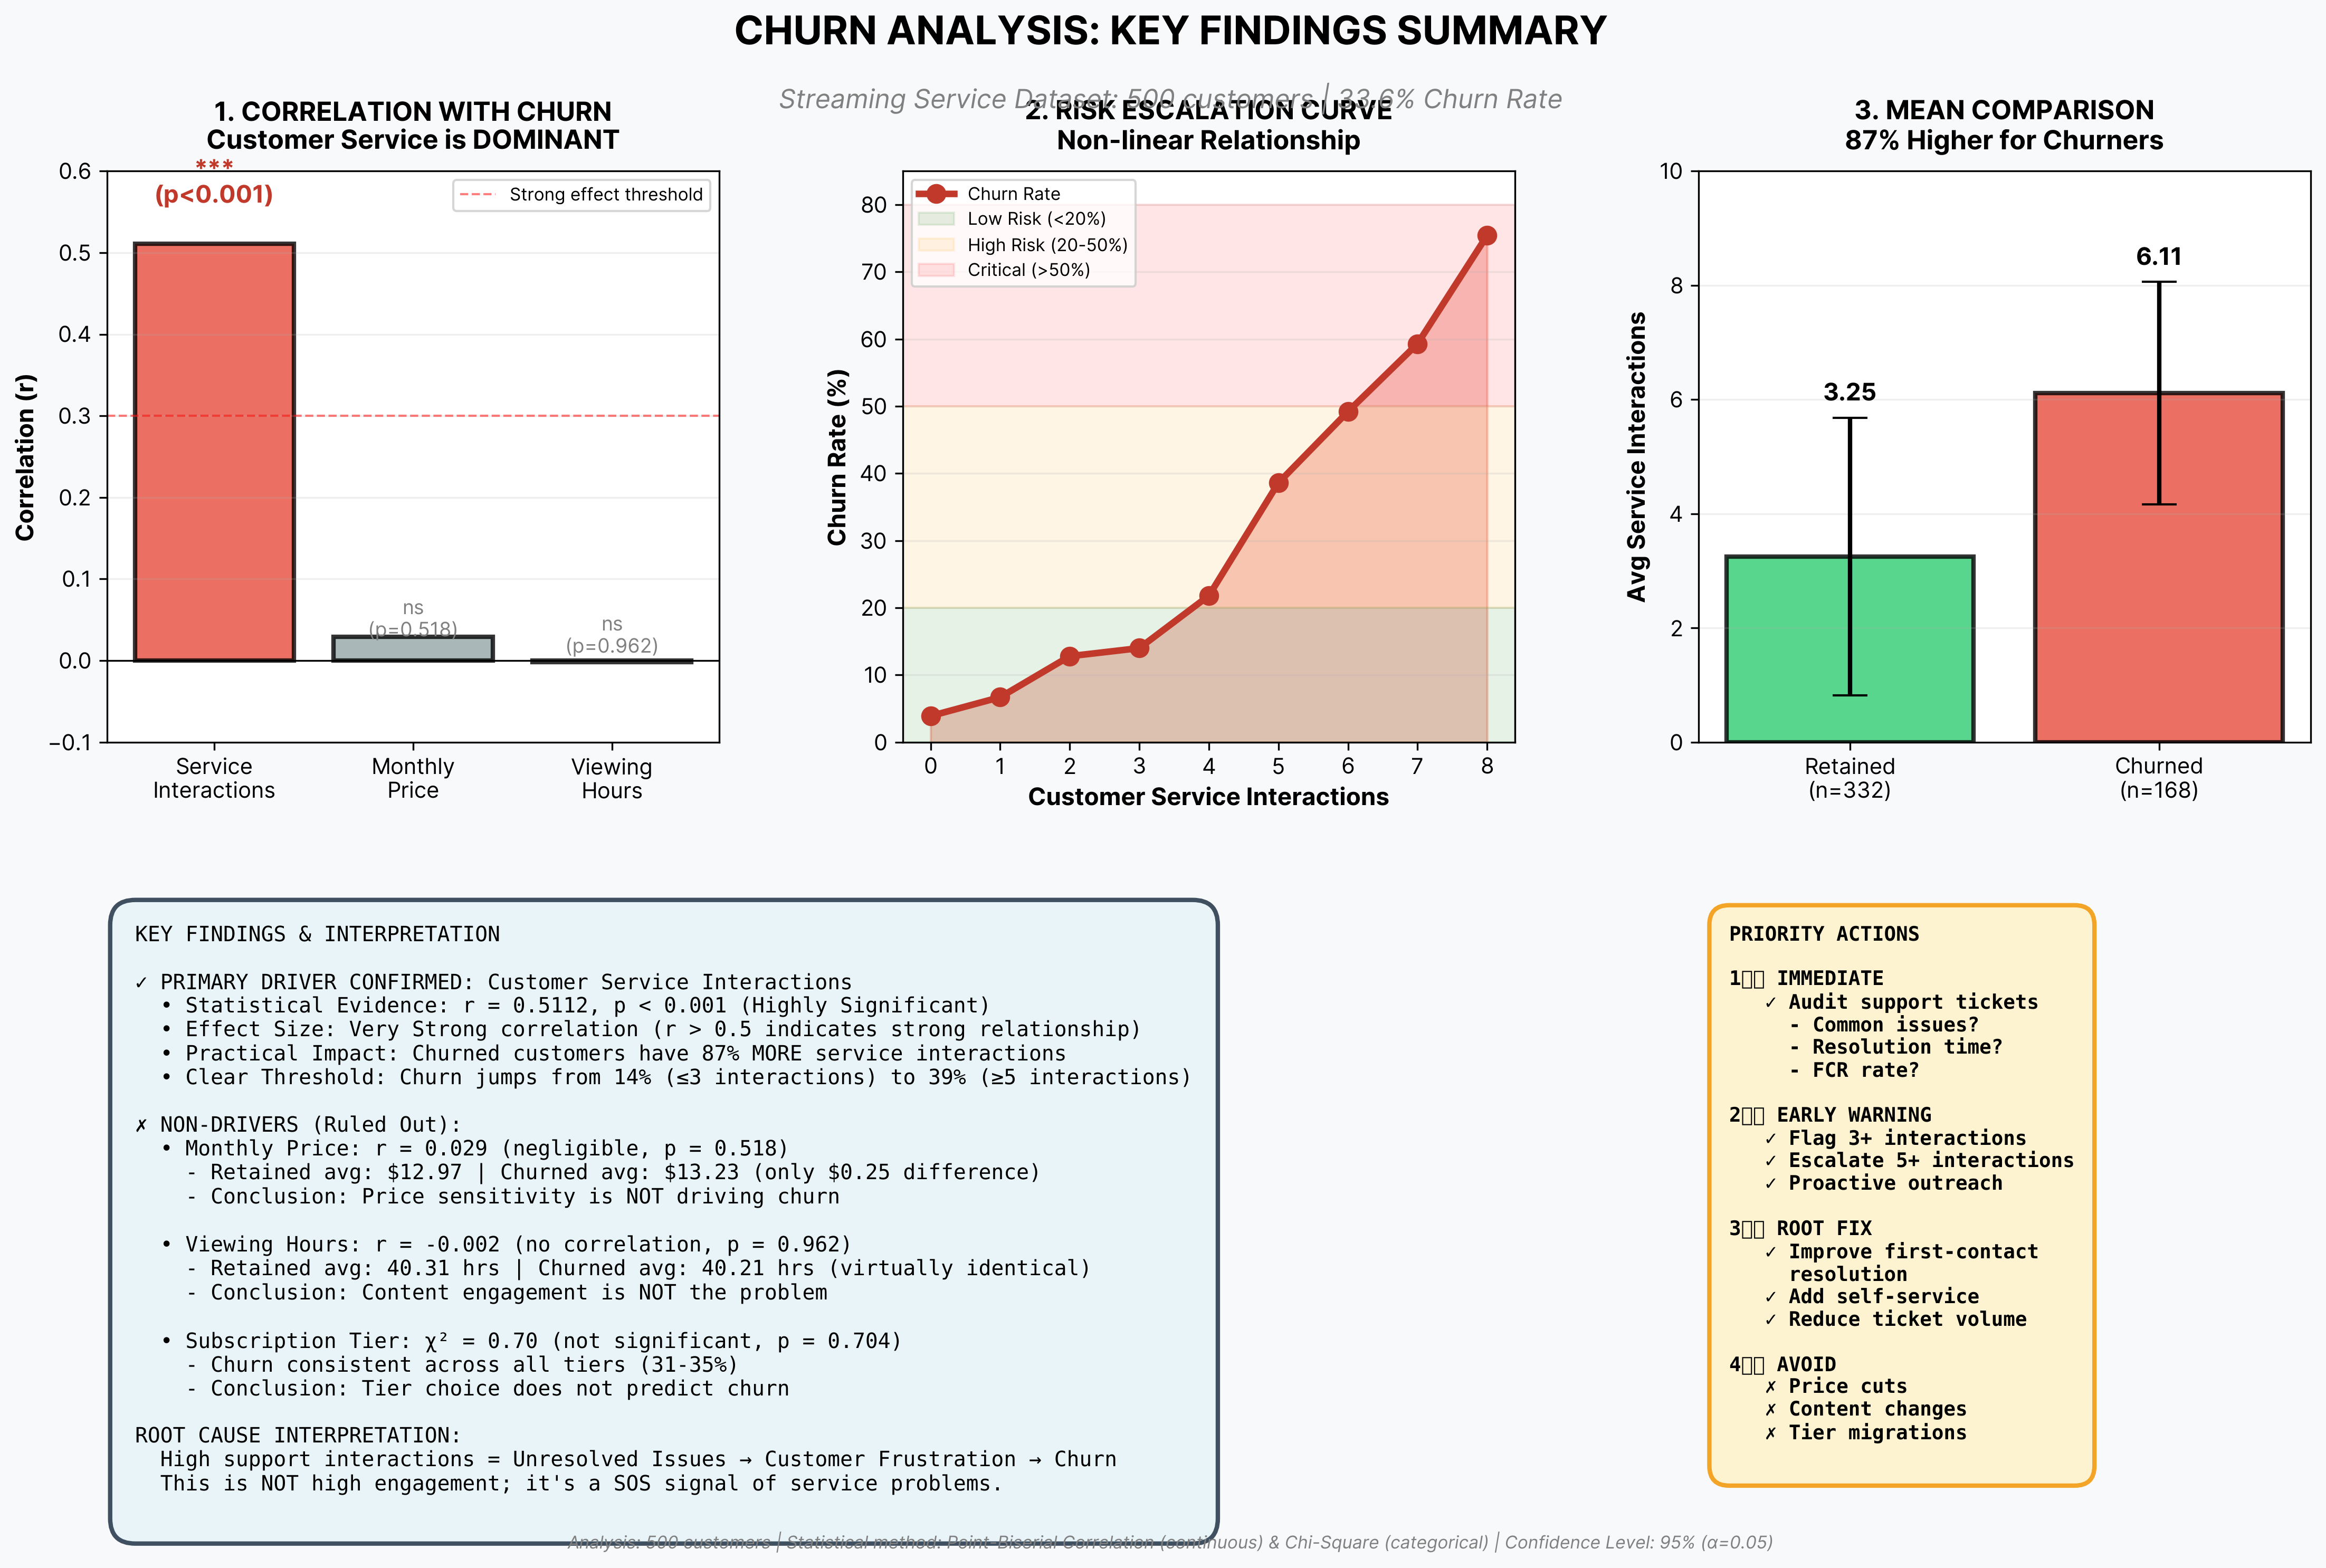

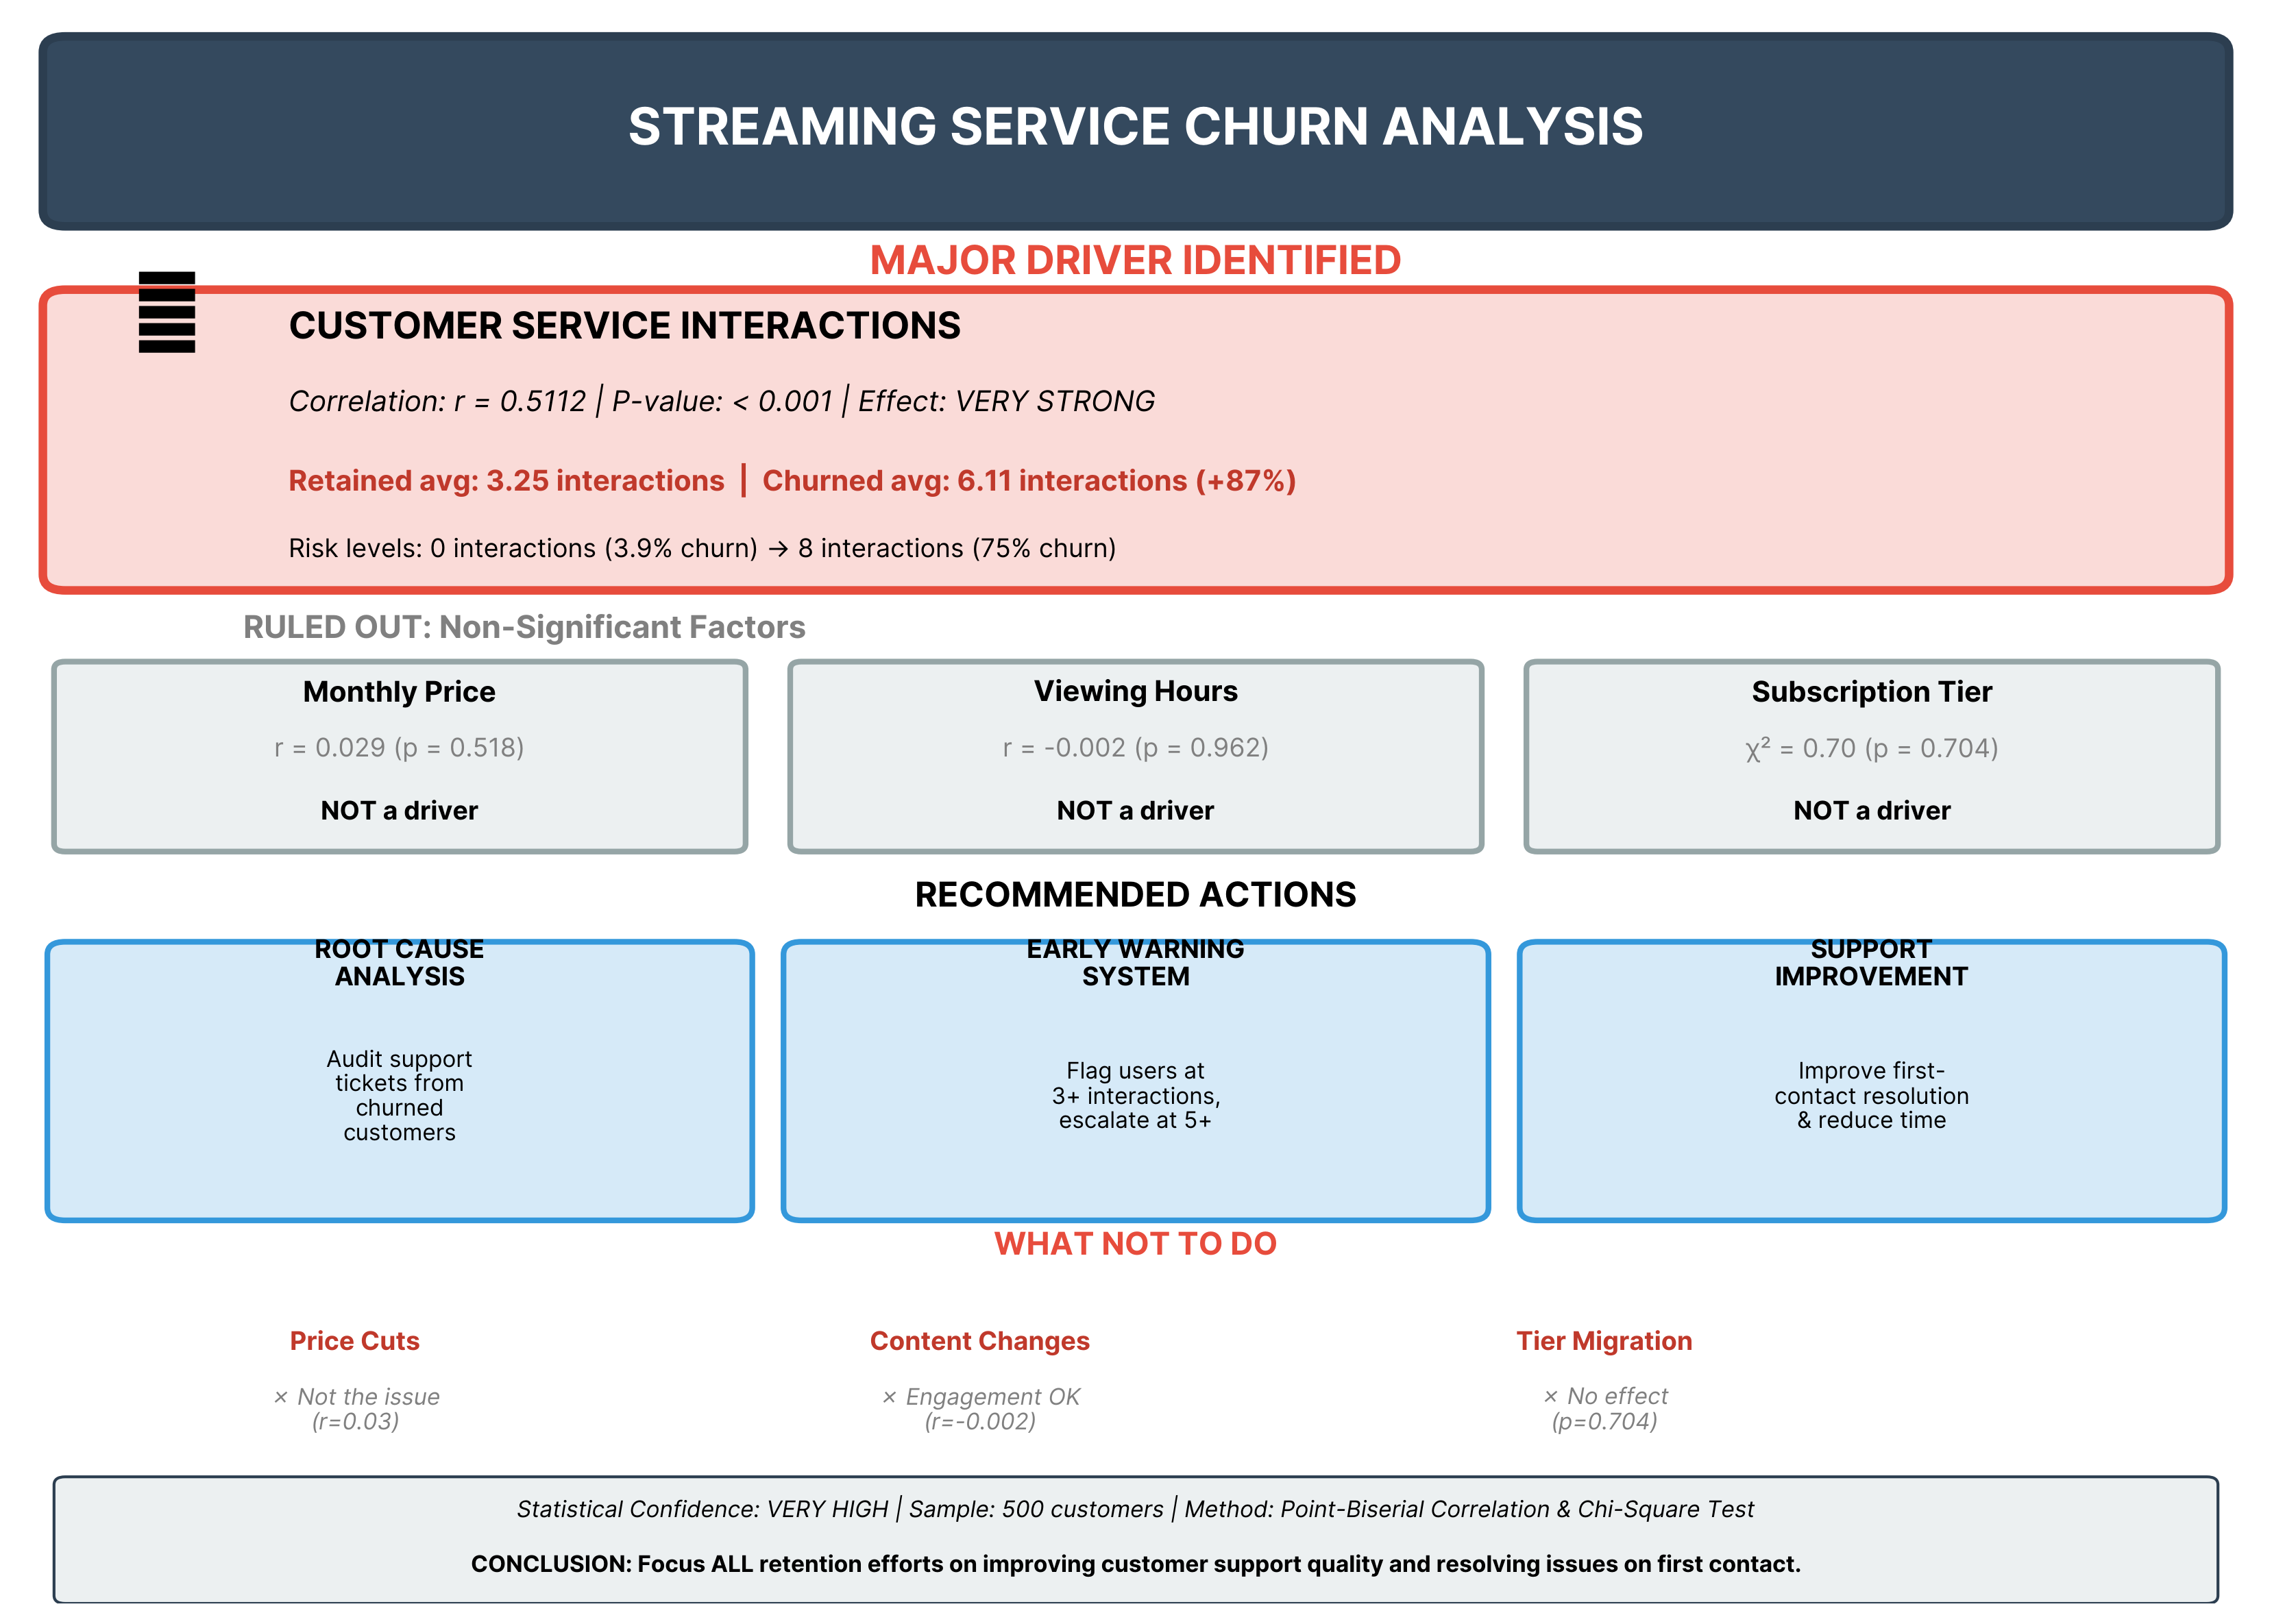

In [10]:
# Show the saved images (needs Pillow, which was installed in lesson 40)
from IPython.display import Image, display

for n in range(1, len(generated_ids) + 1):
    display(Image(filename=f"churn_plot_{n}.png"))

## Clean up the uploaded file

In [11]:
# Uploaded files stay on the server until you delete them
client.beta.files.delete(file_metadata.id)
print("Deleted", file_metadata.id)

Deleted file_01XGyKCfWxSLtsKgX96cnBmo


Notes

- The code runs in Anthropic’s isolated sandbox with no internet, so your computer is never at risk.
- Code execution may be billed separately and may need enabling in your organisation settings, so an error mentioning permissions points there.
- If the Files API upload fails, the lesson’s upload() helper probably wrapped the same call, so paste the error and I will help.